# Recommender Systems and Collaborative Filtering

## Objectives

By the end of this lesson, you should be able to:

1. build a user-item matrix;
2. measure item similarity using cosine similarity;
3. explain the item-item recommendation score equation;
4. generate personalized recommendations using item-item collaborative filtering;
5. interpret Precision@K as a ranking metric;

## Dataset

We will use **MovieLens Latest Small**, maintained by GroupLens Research at the University of Minnesota.

Source: https://grouplens.org/datasets/movielens/latest/

GroupLens reports approximately 100,000 ratings, 3,600 tags, 9,000 movies, and 600 users. The file is about 1 MB.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

BASE_DIR = Path("..").resolve()
DATA_DIR = BASE_DIR / "data"
FIG_DIR = BASE_DIR / "figures"
RESULTS_DIR = BASE_DIR / "results"

ZIP_PATH = DATA_DIR / "ml-latest-small.zip"
EXTRACT_DIR = DATA_DIR / "ml-latest-small"

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 80)

def load_movielens():
    ratings_path = EXTRACT_DIR / "ratings.csv"
    movies_path = EXTRACT_DIR / "movies.csv"

    ratings = pd.read_csv(ratings_path)
    movies = pd.read_csv(movies_path)

    return ratings, movies, "MovieLens Latest Small"

ratings_raw, movies_raw, dataset_name = load_movielens()
print(dataset_name)
print(ratings_raw.shape, movies_raw.shape)
ratings_raw.head()

MovieLens Latest Small
(100836, 4) (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [2]:
dataset_summary = {
    "dataset": dataset_name,
    "users": int(ratings_raw["userId"].nunique()),
    "items": int(ratings_raw["movieId"].nunique()),
    "interactions": int(len(ratings_raw)),
    "min_rating": float(ratings_raw["rating"].min()),
    "max_rating": float(ratings_raw["rating"].max()),
}
dataset_summary

{'dataset': 'MovieLens Latest Small',
 'users': 610,
 'items': 9724,
 'interactions': 100836,
 'min_rating': 0.5,
 'max_rating': 5.0}

## Recommendation is neither classification nor regression

In classification, we want a class, such as failure/no failure, pass/fail, or load type.

In regression, we want a numerical value, such as temperature, power, lifetime, or demand.

In recommendation, the final product is usually a **ranking**: an ordered list of alternatives for a user, project, machine, or operating context.

Even when numerical ratings are used, the practical question is usually: **which items make it into the Top K?**

## User-item matrix

The user-item matrix is denoted by

$$R_{u,i}$$

where:

- $u$ denotes the user;
- $i$ denotes the item;
- $R_{u,i}$ denotes a rating, usage, purchase, click, technical assessment, or observed performance.

In practice, this matrix is sparse: most users have rated only a small fraction of the items.

In [3]:
# To keep the lesson fast, we work with the most-rated items.
# This preserves the behavior of the real problem while avoiding a matrix that is too large for a hands-on lesson.
MAX_ITEMS = 1200
item_counts = ratings_raw.groupby("movieId").size().sort_values(ascending=False)
popular_items = item_counts.head(min(MAX_ITEMS, len(item_counts))).index

ratings = ratings_raw[ratings_raw["movieId"].isin(popular_items)].copy()
movies = movies_raw[movies_raw["movieId"].isin(popular_items)].copy()

user_item = ratings.pivot_table(index="userId", columns="movieId", values="rating")
sparsity = 1.0 - user_item.count().sum() / user_item.size

print(f"User-item matrix: {user_item.shape[0]} users x {user_item.shape[1]} items")
print(f"Observed ratings: {int(user_item.count().sum())}")
print(f"Sparsity: {sparsity:.2%}")
user_item.iloc[:5, :8]

User-item matrix: 610 users x 1200 items
Observed ratings: 65923
Sparsity: 90.99%


movieId,1,2,3,5,6,7,10,11
userId,,,,,,,,
1,4.0,NaN,4.0,NaN,4.0,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


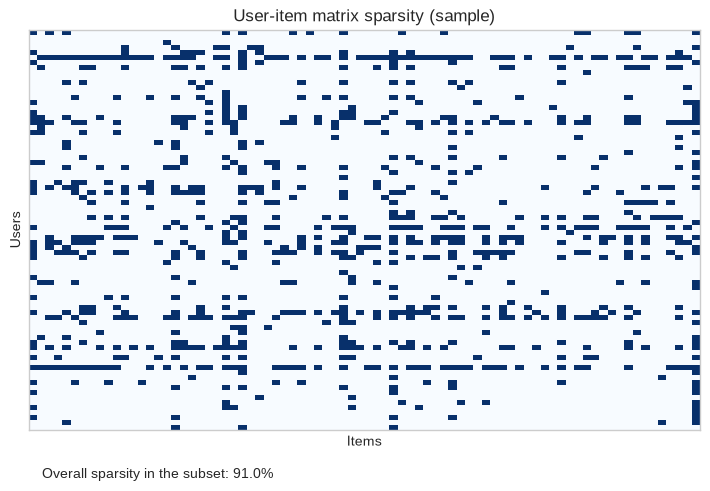

In [4]:
# Figure 1: sparsity in a submatrix
sample = user_item.iloc[:80, :80].notna().astype(int)
fig, ax = plt.subplots(figsize=(7.2, 5.0))
ax.imshow(sample, aspect="auto", cmap="Blues", interpolation="nearest")
ax.set_title("User-item matrix sparsity (sample)")
ax.set_xlabel("Items")
ax.set_ylabel("Users")
ax.set_xticks([])
ax.set_yticks([])
ax.text(0.02, -0.12, f"Overall sparsity in the subset: {sparsity:.1%}", transform=ax.transAxes)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig01_sparsity.png", dpi=180, bbox_inches="tight")
plt.show()

## Cosine similarity

To compare two items, we examine their rating vectors across users.

$$
\operatorname{sim}(a,b)=\frac{a \cdot b}{\|a\|\,\|b\|}
$$

Intuition: two items are similar if users rate them in similar ways.

In engineering, this means two sensors, devices, or procedures are similar if they appear in similar usage and evaluation contexts.

In [5]:
# Train/test split by user.
# We hold out some of each user's ratings for testing when they have enough history.
def split_by_user(df, test_size=0.2, min_interactions=5, random_state=42):
    rng_local = np.random.default_rng(random_state)
    train_idx, test_idx = [], []
    for _, group in df.groupby("userId"):
        idx = group.index.to_numpy()
        if len(idx) < min_interactions:
            train_idx.extend(idx)
            continue
        n_test = max(1, int(round(test_size * len(idx))))
        test_choices = rng_local.choice(idx, size=n_test, replace=False)
        test_set = set(test_choices)
        test_idx.extend(test_choices)
        train_idx.extend([i for i in idx if i not in test_set])
    return df.loc[train_idx].copy(), df.loc[test_idx].copy()

train, test = split_by_user(ratings, random_state=RANDOM_STATE)
train_matrix = train.pivot_table(index="userId", columns="movieId", values="rating")
train_matrix = train_matrix.reindex(index=user_item.index, columns=user_item.columns)

print(train.shape, test.shape)
print(f"Users with test data: {test['userId'].nunique()}")

(52737, 4) (13186, 4)
Users with test data: 609


In [6]:
# Item-item cosine similarity, computed explicitly with NumPy.
# We fill missing values with zero to indicate no observed rating.
item_user_matrix = train_matrix.fillna(0).T

X = item_user_matrix.to_numpy(dtype=float)
norms = np.linalg.norm(X, axis=1, keepdims=True)
X_norm = np.divide(X, norms, out=np.zeros_like(X), where=norms > 0)
similarity = X_norm @ X_norm.T
np.fill_diagonal(similarity, 0.0)

sim_df = pd.DataFrame(similarity, index=item_user_matrix.index, columns=item_user_matrix.index)

sim_df.iloc[:5, :5]


movieId,1,2,3,5,6
movieId,,,,,
1,0.000000,0.350908,0.281987,0.296271,0.284444
2,0.350908,0.000000,0.216096,0.216812,0.244968
3,0.281987,0.216096,0.000000,0.370165,0.192952
5,0.296271,0.216812,0.370165,0.000000,0.254897
6,0.284444,0.244968,0.192952,0.254897,0.000000


In [7]:
def movie_title(movie_id):
    row = movies_raw.loc[movies_raw["movieId"] == movie_id, "title"]
    return row.iloc[0] if len(row) else str(movie_id)


def find_movie_id_by_title(text):
    matches = movies_raw[movies_raw["title"].str.contains(text, case=False, regex=False, na=False)]
    if matches.empty:
        raise ValueError(f"No item found containing: {text}")
    return int(matches.iloc[0]["movieId"])


def similar_items_cosine(movie_id, n=10):
    if movie_id not in sim_df.index:
        raise ValueError("Item outside the subset used in the matrix.")
    sims = sim_df[movie_id].sort_values(ascending=False).head(n)
    return pd.DataFrame({
        "movieId": sims.index,
        "title": [movie_title(mid) for mid in sims.index],
        "similarity": sims.values,
    })

# Classic example: Toy Story is usually in the popular subset.
example_movie_id = find_movie_id_by_title("Toy Story") if dataset_name.startswith("MovieLens") else 1
print(movie_title(example_movie_id))
similar_items_cosine(example_movie_id, n=8)

Toy Story (1995)


,movieId,title,similarity
0,3114,Toy Story 2 (1999),0.491296
1,1210,Star Wars: Episode VI - Return of the Jedi (1983),0.485552
2,588,Aladdin (1992),0.471446
3,788,"Nutty Professor, The (1996)",0.451675
4,34,Babe (1995),0.444210
5,648,Mission: Impossible (1996),0.442048
6,4886,"Monsters, Inc. (2001)",0.442010
7,1265,Groundhog Day (1993),0.438121


## Explicit calculation in this lesson

We do not use a specialized recommendation library. The item-item recommender is implemented step by step in the notebook to make its mechanics clear:

- user-item matrix;
- item-user vectors;
- cosine similarity calculated with NumPy;
- normalized score;
- removal of previously seen items;
- final ranking.

This makes the source of every number in the plots and recommendations clear.


In [8]:
# Example: items most similar to a reference movie using the similarity matrix.
def similar_items(movie_id, n=8):
    if movie_id not in sim_df.index:
        return pd.DataFrame(columns=["movieId", "title", "similarity"])
    similar = sim_df.loc[movie_id].sort_values(ascending=False).head(n)
    return pd.DataFrame({
        "movieId": similar.index,
        "title": [movie_title(mid) for mid in similar.index],
        "similarity": similar.values,
    })

reference_movie = int(item_user_matrix.index[0])
similar_items(reference_movie, n=8)

,movieId,title,similarity
0,3114,Toy Story 2 (1999),0.491296
1,1210,Star Wars: Episode VI - Return of the Jedi (1983),0.485552
2,588,Aladdin (1992),0.471446
3,788,"Nutty Professor, The (1996)",0.451675
4,34,Babe (1995),0.444210
5,648,Mission: Impossible (1996),0.442048
6,4886,"Monsters, Inc. (2001)",0.442010
7,1265,Groundhog Day (1993),0.438121


## Item-item recommendation score

For a user (u) and candidate item (i), we use the same formula implemented in the code:

$$
\operatorname{score}(u,i)=
\frac{\sum_{j \in I_u}\operatorname{sim}(i,j)R_{u,j}}{\sum_{j \in I_u}|\operatorname{sim}(i,j)|}
$$

where:

- (u) is the user receiving recommendations;
- (i) is a candidate movie the user has not rated;
- ($I_u$) is the set of movies already rated by that user in the training set;
- (j) is one of those known movies;
- ($\operatorname{sim}(i,j)$) is the cosine similarity between candidate (i) and known movie (j);
- ($R_{u,j}$) is the rating user (u) gave movie (j).

The numerator sums contributions from known movies. The denominator normalizes by the sum of absolute similarities, reducing the effect of users with many rated movies.


In [9]:
def recommend_item_item(user_id, k=10):
    if user_id not in train_matrix.index:
        return pd.DataFrame(columns=["movieId", "title", "score"])
    user_ratings = train_matrix.loc[user_id]
    seen_items = user_ratings.dropna().index
    ratings_vector = user_ratings.fillna(0).reindex(sim_df.columns).values
    indicator = user_ratings.notna().astype(float).reindex(sim_df.columns).values

    scores = sim_df.values @ ratings_vector
    normalizer = np.abs(sim_df.values) @ indicator
    scores = np.divide(scores, normalizer, out=np.zeros_like(scores), where=normalizer > 0)

    result = pd.DataFrame({"movieId": sim_df.index, "score": scores})
    result = result[~result["movieId"].isin(seen_items)]
    result = result.sort_values("score", ascending=False).head(k)
    result["title"] = result["movieId"].apply(movie_title)
    return result[["movieId", "title", "score"]]

example_user = int(train.groupby("userId").size().sort_values(ascending=False).index[0])
print(f"Example user: {example_user}")
recommend_item_item(example_user, k=10)

Example user: 414


,movieId,title,score
1002,44555,"Lives of Others, The (Das leben der Anderen) (2006)",3.945633
311,1233,"Boot, Das (Boat, The) (1981)",3.936130
581,2599,Election (1999),3.932415
280,1175,Delicatessen (1991),3.932194
236,926,All About Eve (1950),3.915419
216,866,Bound (1996),3.909560
281,1179,"Grifters, The (1990)",3.907575
1140,92259,Intouchables (2011),3.905301
513,2186,Strangers on a Train (1951),3.905040
1160,105504,Captain Phillips (2013),3.903765


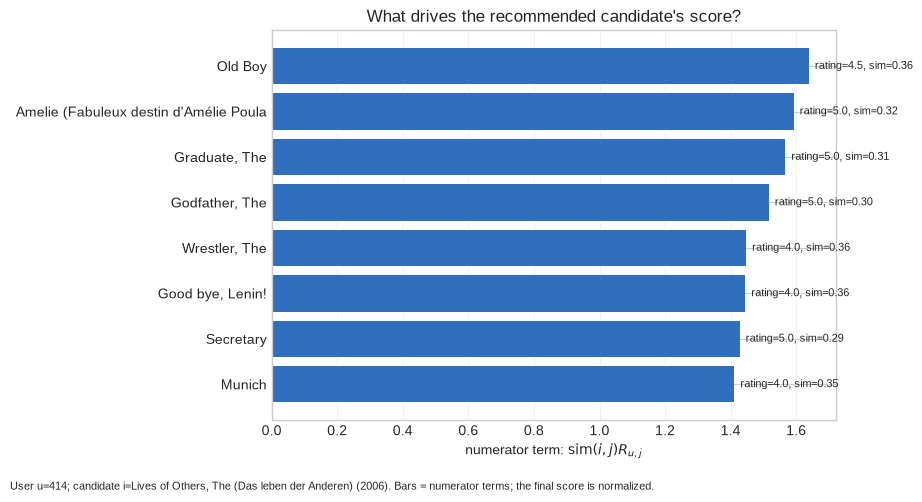

,movieId_j,movie_j,R_u_j,sim_i_j,contribution
671,27773,Old Boy (2003),4.5,0.364152,1.638683
571,4973,"Amelie (Fabuleux destin d'Amélie Poulain, Le) (2001)",5.0,0.318472,1.592362
218,1247,"Graduate, The (1967)",5.0,0.313349,1.566745
149,858,"Godfather, The (1972)",5.0,0.303273,1.516364
766,64839,"Wrestler, The (2008)",4.0,0.361793,1.447172
646,7323,"Good bye, Lenin! (2003)",4.0,0.361154,1.444616
594,5617,Secretary (2002),5.0,0.285515,1.427576
698,41997,Munich (2005),4.0,0.352821,1.411284


In [10]:
# Figure 4: visual decomposition of the score for a real MovieLens user.
def decompose_score(user_id, movie_id, top_n=8):
    user_ratings = train_matrix.loc[user_id].dropna()
    sims = sim_df.loc[movie_id, user_ratings.index]
    parts = pd.DataFrame({
        "movieId_j": user_ratings.index,
        "movie_j": [movie_title(mid) for mid in user_ratings.index],
        "R_u_j": user_ratings.values,
        "sim_i_j": sims.values,
    })
    parts["contribution"] = parts["R_u_j"] * parts["sim_i_j"]
    parts = parts.sort_values("contribution", ascending=False)
    return parts.head(top_n)

example_user = int(train_matrix.count(axis=1).sort_values(ascending=False).index[0])
example_recs = recommend_item_item(example_user, k=5)
candidate_movie = int(example_recs.iloc[0]["movieId"])
score_parts = decompose_score(example_user, candidate_movie, top_n=8)

fig, ax = plt.subplots(figsize=(9.2, 5.0))
plot_parts = score_parts.iloc[::-1].copy()
labels = plot_parts["movie_j"].str.replace(r"\s*\(\d{4}\)", "", regex=True).str.slice(0, 38)
ax.barh(labels, plot_parts["contribution"], color="#2f6fbb")
ax.set_xlabel(r"numerator term: $\operatorname{sim}(i,j)R_{u,j}$")
ax.set_title("What drives the recommended candidate's score?")
ax.grid(axis="x", alpha=0.25)
for y_pos, (_, row) in enumerate(plot_parts.iterrows()):
    ax.text(row["contribution"], y_pos, f"  rating={row['R_u_j']:.1f}, sim={row['sim_i_j']:.2f}", va="center", fontsize=8)
fig.text(
    0.01, 0.01,
    f"User u={example_user}; candidate i={movie_title(candidate_movie)}. Bars = numerator terms; the final score is normalized.",
    fontsize=8,
)
fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig(FIG_DIR / "fig04_score_breakdown.png", dpi=180, bbox_inches="tight")
plt.show()

score_parts[["movieId_j", "movie_j", "R_u_j", "sim_i_j", "contribution"]]


In [11]:
# Popularity baseline: recommends well-rated items with many ratings.
# The teaching idea is simple: before personalizing, see how strong it is to recommend what is already widely accepted.
pop_stats = train.groupby("movieId").agg(
    mean=("rating", "mean"),
    n_ratings=("rating", "size")
).reset_index()
pop_stats["popularity_score"] = pop_stats["mean"] * np.log1p(pop_stats["n_ratings"])
pop_ranking = pop_stats.sort_values("popularity_score", ascending=False)


def recommend_popularity(user_id, k=10):
    seen = set(train.loc[train["userId"] == user_id, "movieId"])
    recs = pop_ranking[~pop_ranking["movieId"].isin(seen)].head(k).copy()
    recs["title"] = recs["movieId"].apply(movie_title)
    return recs[["movieId", "title", "mean", "n_ratings", "popularity_score"]]

pop_ranking.head(10).assign(title=lambda d: d["movieId"].apply(movie_title))[
    ["movieId", "title", "mean", "n_ratings", "popularity_score"]
]


,movieId,title,mean,n_ratings,popularity_score
98,318,"Shawshank Redemption, The (1994)",4.408163,245,24.268400
112,356,Forrest Gump (1994),4.117424,264,22.974115
91,296,Pulp Fiction (1994),4.158996,239,22.793954
576,2571,"Matrix, The (1999)",4.193694,222,22.676022
171,593,"Silence of the Lambs, The (1991)",4.146119,219,22.362620
79,260,Star Wars: Episode IV - A New Hope (1977),4.210256,195,22.222216
636,2959,Fight Club (1999),4.231638,177,21.927434
286,1196,Star Wars: Episode V - The Empire Strikes Back (1980),4.218391,174,21.787086
25,50,"Usual Suspects, The (1995)",4.227273,165,21.609767
153,527,Schindler's List (1993),4.197605,167,21.508376


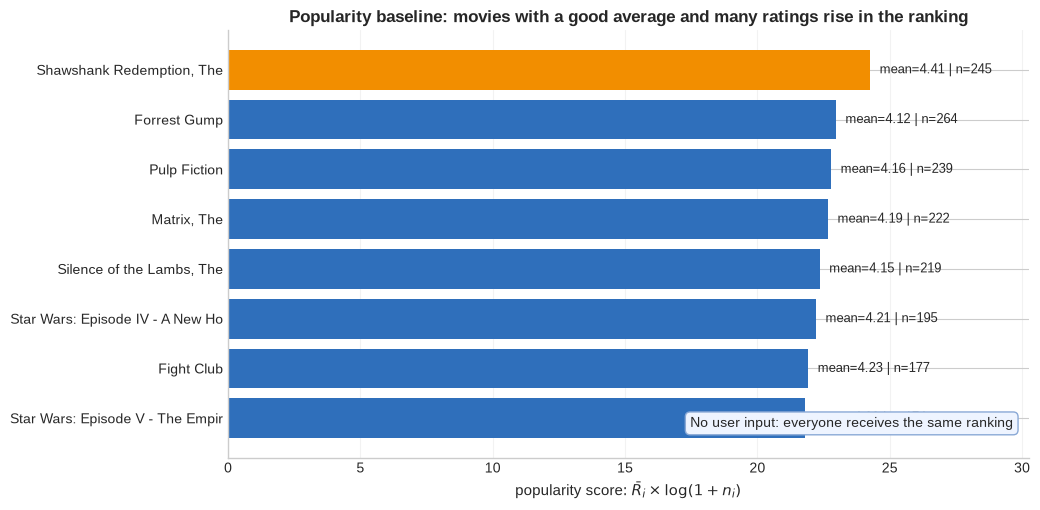

In [12]:
# Figure 2: popularity baseline with a readable ranking.
most_popular = pop_ranking.head(8).copy()
most_popular["short_title"] = most_popular["movieId"].apply(movie_title).str.replace(r"\s*\(\d{4}\)", "", regex=True)
most_popular["short_title"] = most_popular["short_title"].str.slice(0, 32)

y = np.arange(len(most_popular))[::-1]
fig, ax = plt.subplots(figsize=(10.5, 5.2))
colors = ["#f28e00" if i == 0 else "#2f6fbb" for i in range(len(most_popular))]
ax.barh(y, most_popular["popularity_score"], color=colors)
ax.set_yticks(y)
ax.set_yticklabels(most_popular["short_title"], fontsize=10)
ax.set_xlabel(r"popularity score: $\bar{R}_i \times \log(1+n_i)$", fontsize=11)
ax.set_title("Popularity baseline: movies with a good average and many ratings rise in the ranking", fontsize=12, weight="bold")
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

for pos, (_, row) in zip(y, most_popular.iterrows()):
    label = f"mean={row['mean']:.2f} | n={int(row['n_ratings'])}"
    ax.text(row["popularity_score"] + 0.35, pos, label, va="center", fontsize=9)

limit = most_popular["popularity_score"].max() + 6
ax.set_xlim(0, limit)
ax.text(
    0.98, 0.08,
    "No user input: everyone receives the same ranking",
    transform=ax.transAxes, ha="right", va="center", fontsize=10,
    bbox={"boxstyle": "round,pad=0.35", "facecolor": "#eef4ff", "edgecolor": "#8aa9d6"},
)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig02_popularity.png", dpi=180, bbox_inches="tight")
plt.show()


## Evaluation: Precision@K

In recommendation, we evaluate ranking quality. For each user, we inspect the first (K) recommended items and count how many were relevant in the test set.

$$
\operatorname{Precision@K}=\frac{\text{relevant items recommended in the Top K}}{K}
$$

A movie is considered relevant if it appears in the test set with a rating greater than or equal to 4.0.

For example, if (K=10) and 3 of the 10 recommended movies are relevant, then ($\operatorname{Precision@10}=3/10=0.30)$.

This metric is not classification accuracy. It asks: **does the top of the list contain good recommendations?**


In [13]:
def precision_at_k(recommended, relevant, k):
    recommended_at_k = list(recommended)[:k]
    if k == 0:
        return 0.0
    return len(set(recommended_at_k) & set(relevant)) / k


def evaluate_model(recommend_func, ks=(5, 10, 20), relevance_threshold=4.0):
    relevant_by_user = (
        test[test["rating"] >= relevance_threshold]
        .groupby("userId")["movieId"]
        .apply(set)
        .to_dict()
    )
    rows = []
    for k in ks:
        values = []
        for user_id, relevant in relevant_by_user.items():
            if not relevant:
                continue
            recs = recommend_func(user_id, k=k)
            values.append(precision_at_k(recs["movieId"].tolist(), relevant, k))
        rows.append({
            "K": k,
            "Precision@K": float(np.mean(values)) if values else 0.0,
            "evaluated_users": len(values),
        })
    return pd.DataFrame(rows)

evaluation_item = evaluate_model(recommend_item_item)
evaluation_item["model"] = "Item-item"
evaluation_pop = evaluate_model(recommend_popularity)
evaluation_pop["model"] = "Popularity"
evaluation = pd.concat([evaluation_item, evaluation_pop], ignore_index=True)
evaluation


,K,Precision@K,evaluated_users,model
0,5,0.013153,593,Item-item
1,10,0.018550,593,Item-item
2,20,0.020826,593,Item-item
3,5,0.164587,593,Popularity
4,10,0.129005,593,Popularity
5,20,0.099578,593,Popularity


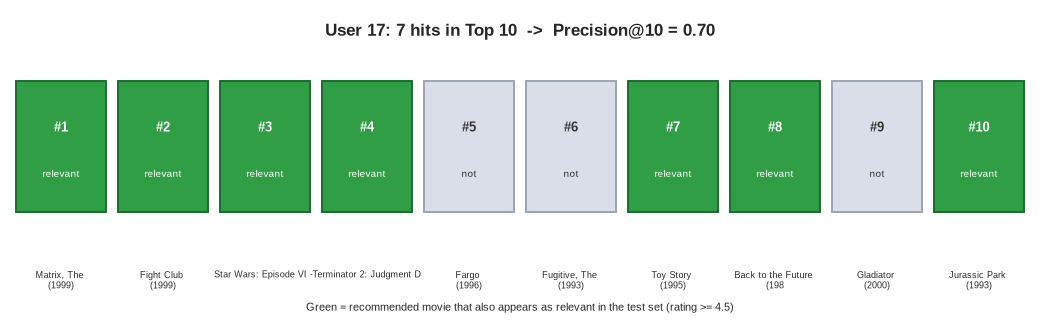

In [14]:
# Figure 6: visual example of Precision@10 using real recommendations.
def find_precision_example(recommend_func, k=10, relevance_threshold=4.0):
    relevant_by_user = (
        test[test["rating"] >= relevance_threshold]
        .groupby("userId")["movieId"]
        .apply(set)
        .to_dict()
    )
    best = None
    for user_id, relevant in relevant_by_user.items():
        recs = recommend_func(user_id, k=k)
        if recs.empty:
            continue
        hits = [mid in relevant for mid in recs["movieId"].tolist()[:k]]
        n_hits = sum(hits)
        if best is None or n_hits > best["n_hits"]:
            best = {"user_id": user_id, "recs": recs.head(k).copy(), "hits": hits, "n_hits": n_hits, "relevant": relevant}
    return best

precision_example = find_precision_example(recommend_popularity, k=10, relevance_threshold = 4.5)
fig, ax = plt.subplots(figsize=(10.5, 3.4))
ax.set_xlim(0, 10)
ax.set_ylim(0, 1)
ax.axis("off")
for pos, (_, row) in enumerate(precision_example["recs"].iterrows()):
    hit = precision_example["hits"][pos]
    color = "#2f9e44" if hit else "#d9dee8"
    edge = "#1b6b31" if hit else "#9aa4b2"
    rect = plt.Rectangle((pos + 0.06, 0.35), 0.88, 0.42, facecolor=color, edgecolor=edge, linewidth=1.4)
    ax.add_patch(rect)
    ax.text(pos + 0.50, 0.62, f"#{pos+1}", ha="center", va="center", fontsize=9, weight="bold", color="white" if hit else "#333333")
    ax.text(pos + 0.50, 0.47, "relevant" if hit else "not", ha="center", va="center", fontsize=7, color="white" if hit else "#333333")
    title = movie_title(int(row["movieId"])).replace("(", "\n(")
    ax.text(pos + 0.50, 0.16, title[:24], ha="center", va="top", fontsize=6.5)
example_precision = precision_example["n_hits"] / 10
ax.text(5, 0.93, f"User {precision_example['user_id']}: {precision_example['n_hits']} hits in Top 10  ->  Precision@10 = {example_precision:.2f}", ha="center", va="center", fontsize=12, weight="bold")
ax.text(5, 0.03, "Green = recommended movie that also appears as relevant in the test set (rating >= 4.5)", ha="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig06_precision_example.png", dpi=180, bbox_inches="tight")
plt.show()


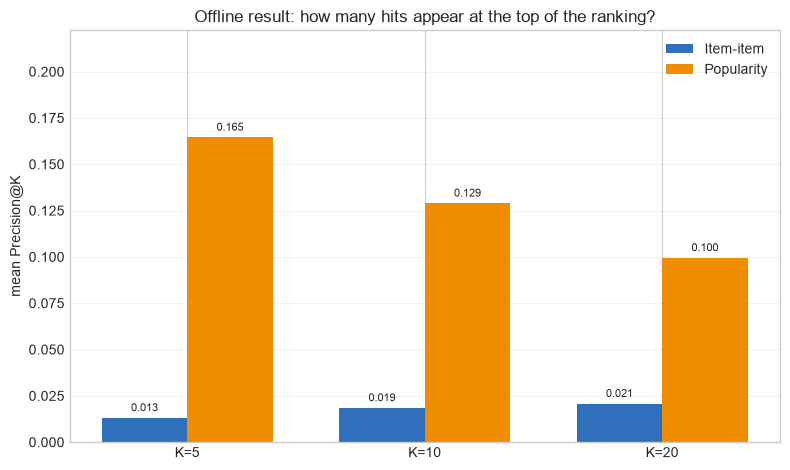

model,K,Item-item,Popularity
0,5,0.013153,0.164587
1,10,0.018550,0.129005
2,20,0.020826,0.099578


In [15]:
# Figure 3: Precision@K comparison with grouped bars.
fig, ax = plt.subplots(figsize=(8.0, 4.8))
models = ["Item-item", "Popularity"]
ks = sorted(evaluation["K"].unique())
x = np.arange(len(ks))
width = 0.36
colors = {"Item-item": "#2f6fbb", "Popularity": "#f08c00"}

for offset, model in zip([-width/2, width/2], models):
    group = evaluation[evaluation["model"] == model].set_index("K").loc[ks]
    bars = ax.bar(x + offset, group["Precision@K"], width, label=model, color=colors[model])
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in group["Precision@K"]], padding=3, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([f"K={k}" for k in ks])
ax.set_ylabel("mean Precision@K")
ax.set_title("Offline result: how many hits appear at the top of the ranking?")
ax.set_ylim(0, max(evaluation["Precision@K"]) * 1.35)
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig03_precision_k.png", dpi=180, bbox_inches="tight")
plt.show()

evaluation_pivot = evaluation.pivot(index="K", columns="model", values="Precision@K").reset_index()
evaluation_pivot


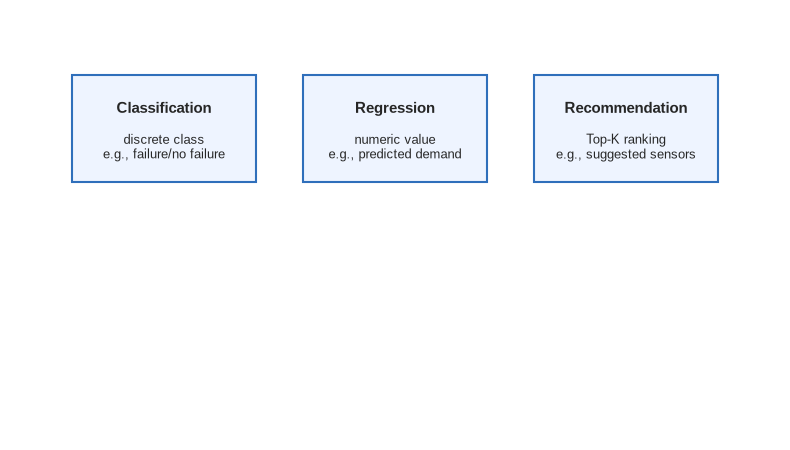

In [16]:
# Figure 5: conceptual comparison of tasks
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.axis("off")
boxes = [
    (0.08, 0.60, "Classification", "discrete class\ne.g., failure/no failure"),
    (0.38, 0.60, "Regression", "numeric value\ne.g., predicted demand"),
    (0.68, 0.60, "Recommendation", "Top-K ranking\ne.g., suggested sensors"),
]
for x, y, title, text in boxes:
    rect = plt.Rectangle((x, y), 0.24, 0.25, facecolor="#eef4ff", edgecolor="#2f6fbb", linewidth=1.5)
    ax.add_patch(rect)
    ax.text(x + 0.12, y + 0.17, title, ha="center", va="center", weight="bold", fontsize=11)
    ax.text(x + 0.12, y + 0.08, text, ha="center", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig05_ml_tasks.png", dpi=180, bbox_inches="tight")
plt.show()